In [1]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models                                   # type: ignore 

from tensorflow.keras.layers import Dropout, Dense, GlobalAveragePooling2D    # type: ignore 
from tensorflow.keras.preprocessing.image import ImageDataGenerator           # type: ignore 

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint # type: ignore

In [2]:
# Train Augmentation Setup (Rescale REMOVED because MobileNet Preprocessing is used below)
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation Setup (No Augmentation, No Rescaling)
val_datagen = ImageDataGenerator()

test_datagen = ImageDataGenerator()

In [3]:
# TRAIN GENERATOR:
train_generator = train_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/train', 
    target_size=(224, 224),
    batch_size=32, 
    class_mode='categorical',
    shuffle=True
)

# VALIDATION GENERATOR:
val_generator = val_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/validate',
    target_size=(224, 224), 
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)


num_classes = train_generator.num_classes
print(f"Total classes to detect: {num_classes}")

Found 10450 images belonging to 51 classes.
Found 1761 images belonging to 51 classes.
Total classes to detect: 51


In [4]:
class_names = list(train_generator.class_indices.keys())
print(class_names)

['Aloe_Vera', 'Bird_of_Paradise', 'Black_Sage', 'Bladderpod', 'Blue_Elderberry', 'Blue_Gum_Eucalyptus', 'Bougainvillea', 'CA_Bush_Sunflower', 'California_Buckwheat', 'California_Poppy', 'California_Sagebrush', 'Castor_Bean', 'Ceanothus_CA_Lilac', 'Chalk_Dudleya', 'Coast_Live_Oak', 'Common_Fennel', 'English_Ivy', 'European_Olive', 'Fiddle_Leaf_Fig', 'Flamingo_Flower', 'French_Lavender', 'Golden_Pothos', 'Heartleaf_Philodendron', 'Ice_Plant', 'Indoor_Rose', 'Jacaranda', 'Jade_Plant', 'Joshua_Tree', 'Manzanita', 'Mariposa_Lily', 'Matilija_Poppy', 'Meyer_Lemon', 'Mustard_Plant', 'Our_Lords_Candle', 'Palo_Verde', 'Peace_Lily', 'Poison_Hemlock', 'Prickly_Pear', 'Rosemary', 'Rubber_Plant', 'Snake_Plant', 'Spider_Plant', 'Sticky_Monkey-flower', 'Stinknet', 'Swiss_Cheese_Plant', 'Toyon', 'Tree_Tobacco', 'Western_Poison_Oak', 'Western_Sycamore', 'Wild_Radish', 'ZZ_Plant']


In [5]:
# 3. MODEL ARCHITECTURE
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = True

# Level 50 Deep Unfreezing
fine_tune_at = 50 
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

# MobileNetV2 expects raw pixels [0, 255] and converts them to [-1, 1] internally:
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=True) 

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x) 

outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

In [6]:
# Ensure models directory exists
os.makedirs("04_Models", exist_ok=True)

In [7]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 51)             │        65,331 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,328,435 (8.88 MB)

 Trainable params: 2,242,483 (8.55 MB)

 Non-trainable params: 85,952 (335.75 KB)

In [8]:
# Load best trained model weights
model = tf.keras.models.load_model("04_Models/caliplant_v5.keras")


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.000005),    # Ultra-small LR for V5 Deep Learning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compilation done!!")



# Slightly higher patience for fine-tuning extension
early_stop = EarlyStopping(
    monitor='val_accuracy', 
    patience=5, 
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=3, 
    min_lr=1e-8
)

checkpoint = ModelCheckpoint(
    "04_Models/caliplant_v5_extented.keras", 
    monitor='val_accuracy', 
    save_best_only=True
)

print("Starting Fine-Tuning Phase 2 (Epochs 41 to 70)...")

# Continue training for 30 more epochs
history = model.fit(
    train_generator,
    epochs=35,
    validation_data=val_generator,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Model compilation done!!
Starting Fine-Tuning Phase 2 (Epochs 41 to 70)...
Epoch 1/35
208/327 ━━━━━━━━━━━━━━━━━━━━ 1:22 694ms/step - accuracy: 0.8613 - loss: 0.4753

c:\Users\sanch\Documents\Git_hub\CaliPlant_AI\ai_env\Lib\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


327/327 ━━━━━━━━━━━━━━━━━━━━ 278s 809ms/step - accuracy: 0.8568 - loss: 0.5006 - val_accuracy: 0.7990 - val_loss: 0.6896 - learning_rate: 5.0000e-06
Epoch 2/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 251s 767ms/step - accuracy: 0.8621 - loss: 0.4885 - val_accuracy: 0.8024 - val_loss: 0.6808 - learning_rate: 5.0000e-06
Epoch 3/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 240s 735ms/step - accuracy: 0.8624 - loss: 0.4749 - val_accuracy: 0.8075 - val_loss: 0.6675 - learning_rate: 5.0000e-06
Epoch 4/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 243s 744ms/step - accuracy: 0.8691 - loss: 0.4734 - val_accuracy: 0.8126 - val_loss: 0.6553 - learning_rate: 5.0000e-06
Epoch 5/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 242s 738ms/step - accuracy: 0.8707 - loss: 0.4482 - val_accuracy: 0.8132 - val_loss: 0.6523 - learning_rate: 5.0000e-06
Epoch 6/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 246s 752ms/step - accuracy: 0.8713 - loss: 0.4549 - val_accuracy: 0.8160 - val_loss: 0.6434 - learning_rate: 5.0000e-06
Epoch 7/35
327/327 ━━━━━━━━━━━━━━━━━━━━ 290s 887ms/

In [ ]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# SECTION 5: TEST GENERATOR (For evaluation)
test_generator = test_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # CRITICAL: Isko False hi rakhna hai evaluation ke liye
)

Found 868 images belonging to 51 classes.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Evaluating model on test dataset...")

# 1. Test images par predictions nikalna
predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

In [ ]:
# 2. True (Original) labels nikalna
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

In [13]:
#  SECTION A: OVERALL TEST ACCURACY :Pura dataset par overall evaluation
test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print("\n" + "="*50)
print(f"Final Test Accuracy: {test_acc*100:.2f}%")
print(f"Final Test Loss:     {test_loss:.4f}")
print("="*50 + "\n")


Final Test Accuracy: 84.33%
Final Test Loss:     0.6334



In [14]:
# Print Detailed Classification Report
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


--- CLASSIFICATION REPORT ---
                        precision    recall  f1-score   support

             Aloe_Vera       0.89      0.62      0.73        13
      Bird_of_Paradise       0.85      0.79      0.81        14
            Black_Sage       0.68      0.79      0.73        19
            Bladderpod       0.94      0.84      0.89        19
       Blue_Elderberry       0.88      0.88      0.88        25
   Blue_Gum_Eucalyptus       0.71      0.85      0.77        20
         Bougainvillea       0.87      0.83      0.85        24
     CA_Bush_Sunflower       0.83      0.91      0.87        11
  California_Buckwheat       0.86      0.78      0.82        23
      California_Poppy       0.92      0.96      0.94        23
  California_Sagebrush       0.73      0.85      0.79        13
           Castor_Bean       0.88      0.92      0.90        24
    Ceanothus_CA_Lilac       0.96      0.92      0.94        25
         Chalk_Dudleya       0.86      1.00      0.92        24
        

Loading trained model...
Found 868 images belonging to 51 classes.
Generating predictions on test set...
28/28 ━━━━━━━━━━━━━━━━━━━━ 15s 508ms/step


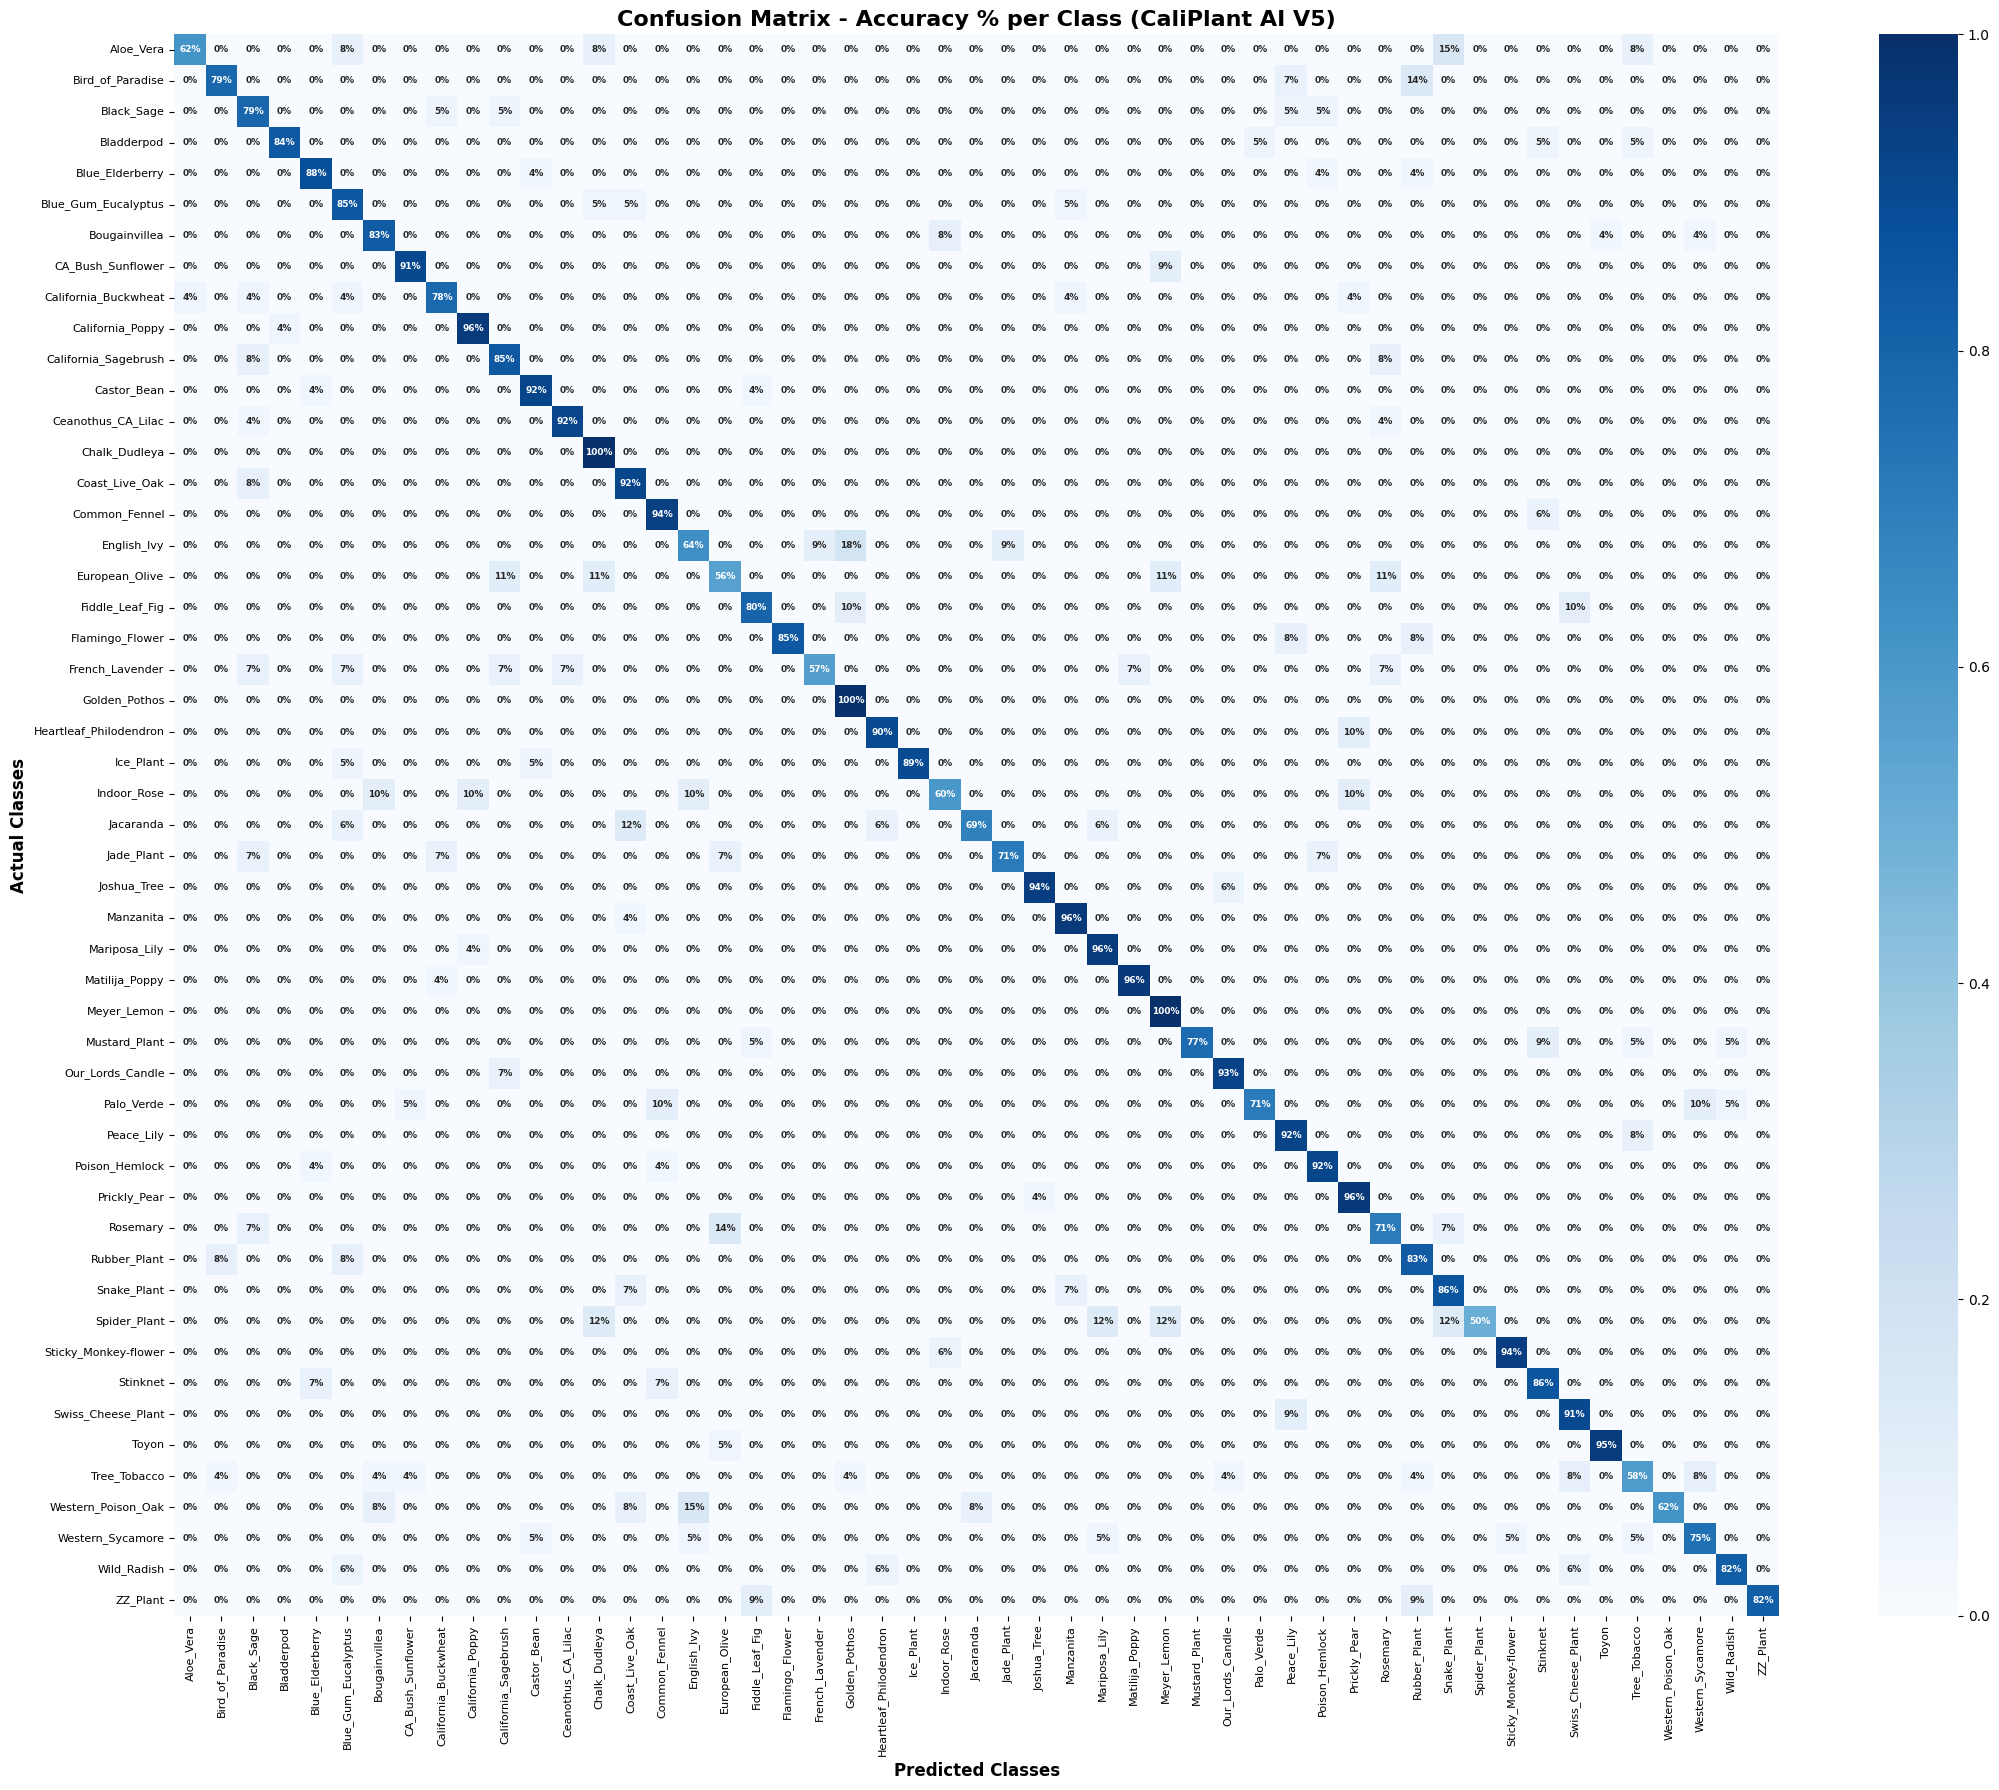

In [ ]:

from sklearn.metrics import confusion_matrix

#  Normalized Confusion Matrix Plot
cm = confusion_matrix(true_classes, predicted_classes)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt='.0%', 
    cmap='Blues', 
    cbar=True,
    xticklabels=class_labels, 
    yticklabels=class_labels,
    annot_kws={"size": 6.5, "weight": "bold"}
)

plt.title('Confusion Matrix - Accuracy % per Class (CaliPlant AI V5)', fontsize=16, fontweight='bold')
plt.ylabel('Actual Classes', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Classes', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()